# Prior vs evidence in LLaVA-1.5-7B: format screen, full run, analysis, probes

**What this notebook does (one run, top to bottom, roughly 1 hour on a Kaggle T4/P100 GPU):**

1. **Format screen** (about 20 min). Tries 5 ways of giving the model the block prior as text, plus a no-history control, on 300 trials each. A format *passes* if (pre-fixed, not tuned after seeing results): image swing is at least 70% of the no-history swing, and gamma >= 0.25 with a 95% interval above 0.
2. **Full run** (about 35 min) on the chosen format: 600 trials, with and without history, saving the last-position residual stream at every layer.
3. **Analysis**: swing by contrast, fit of `delta = b + beta*s + gamma*prior`, side-matched prior effect (overall and per contrast), prior effect in contrast units (for the mouse comparison), plots.
4. **Probes**: layer-by-layer linear decoding of the grating side and of the block prior from the residual stream.
5. **Summary block** to paste back, plus a zip of all small result files.

**Before you run:** turn on a GPU (Settings, Accelerator) and Internet (needed to download the model).
**For safety:** use *Save Version -> Save & Run All (Commit)* so outputs survive a dead session. Every stage also checkpoints to `/kaggle/working/run`, and re-running the notebook resumes from there.

`delta` = logit(Right) - logit(Left) of the first answer token. Positive means the model says Right.

In [1]:
# ===================== CONFIG (edit here) =====================
MOCK = False               # True = fake model, only for testing the pipeline
SEED = 0
FOUR_BIT = True
CONTRASTS = [0.0, 0.03, 0.045, 0.0625, 0.09, 0.125, 1.0]   # ladder from the low-contrast baseline
N_SCREEN, SCREEN_UNBIASED = 300, 20     # screen: trials per condition, length of the 50/50 opening
N_FULL, FULL_UNBIASED = 600, 90
CHUNK = 50                 # full-run checkpoint size (trials)
GRADED_MAX = 0.09          # fit beta/gamma only up to this contrast (12.5% and 100% saturate)
MIN_SWING_RATIO, MIN_GAMMA = 0.70, 0.25   # pre-fixed pass criteria for a history format
FORCE_FORMAT = None        # e.g. "prob30" to skip the automatic choice
RUN_FULL_ANYWAY = True     # if no format passes, still run the full stage on the closest one
import os, json
OUTDIR = "/kaggle/working/run" if os.path.exists("/kaggle/working") else "./run"
if MOCK:
    N_SCREEN, N_FULL, CHUNK, FULL_UNBIASED, SCREEN_UNBIASED = 120, 360, 60, 30, 10
os.makedirs(OUTDIR, exist_ok=True)
# guard: checkpoints in OUTDIR are only reused if the settings are unchanged
_cfg = dict(SEED=SEED, CONTRASTS=CONTRASTS, N_SCREEN=N_SCREEN, SCREEN_UNBIASED=SCREEN_UNBIASED,
            N_FULL=N_FULL, FULL_UNBIASED=FULL_UNBIASED, CHUNK=CHUNK, MOCK=MOCK)
_cfgp = f"{OUTDIR}/run_config.json"
if os.path.exists(_cfgp):
    assert json.load(open(_cfgp)) == json.loads(json.dumps(_cfg)), (
        f"Settings differ from the saved run in {OUTDIR}. Delete that folder to start fresh, or restore the old settings.")
else:
    json.dump(_cfg, open(_cfgp, "w"))
print("MOCK =", MOCK, "| outputs ->", OUTDIR)

MOCK = False | outputs -> /kaggle/working/run


In [2]:
import re, time, json, math, shutil, warnings
from datetime import datetime, timedelta, timezone
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

IST = timezone(timedelta(hours=5.5))
SIZE = 336
_Y, _X = np.mgrid[0:SIZE, 0:SIZE].astype(np.float32)
GAP = 2 * np.log(0.8 / 0.2)          # 2.77: log-odds gap between the 0.2 and 0.8 blocks

def make_trials(n, seed, contrasts, n_unbiased):
    """IBL-like blocks. Block lengths 20-100 (truncated exponential) are from memory of the IBL protocol."""
    rng = np.random.default_rng(seed)
    p = np.full(n, 0.5)
    t, cur = n_unbiased, float(rng.choice([0.2, 0.8]))
    while t < n:
        L = 20 + int(rng.exponential(60))
        while L > 100:
            L = 20 + int(rng.exponential(60))
        p[t:t + L] = cur
        t, cur = t + L, round(1.0 - cur, 2)
    side = np.where(rng.random(n) < p, "right", "left")
    c = rng.choice(contrasts, n)
    return dict(n=n, p_right=p, side=side, contrast=c,
                dx=rng.uniform(-15, 15, n), dy=rng.uniform(-30, 30, n), phi=rng.uniform(0, 2 * np.pi, n))

def render(T, t, seed):
    """Small Gabor on gray, jittered position/phase, pixel noise (same stimulus as 'gabor_small' in the baseline)."""
    cx = SIZE / 2 + (84 if T["side"][t] == "right" else -84) + T["dx"][t]
    cy = SIZE / 2 + T["dy"][t]
    env = np.exp(-((_X - cx) ** 2 + (_Y - cy) ** 2) / (2 * 36 ** 2))
    a = 0.5 + 0.5 * T["contrast"][t] * env * np.sin(2 * np.pi * (_X - cx) / 24 + T["phi"][t])
    a = a + np.random.default_rng(seed * 100003 + t).normal(0, 0.02, a.shape)
    return Image.fromarray(np.stack([(np.clip(a, 0, 1) * 255).astype(np.uint8)] * 3, -1))

# ---- history formats (the thing being screened) ----
INSTR = " If the image is unclear, use this information."
FORMATS = {
    "counts30":       dict(window=30, kind="counts", instr=False),   # the format used so far (reference)
    "prob30":         dict(window=30, kind="prob",   instr=False),   # explicit probability
    "counts30+instr": dict(window=30, kind="counts", instr=True),    # counts + short instruction
    "counts10":       dict(window=10, kind="counts", instr=False),   # shorter history
    "prob30+instr":   dict(window=30, kind="prob",   instr=True),    # explicit probability + instruction
}

def hist_counts(T, t, w):
    past = T["side"][max(0, t - w):t]
    return len(past), int((past == "right").sum())

def history_text(T, t, fmt):
    f = FORMATS[fmt]
    n, nr = hist_counts(T, t, f["window"])
    if n == 0:
        return "No previous trials."
    if f["kind"] == "counts":
        base = f"In the last {n} trials the grating was on the left {n - nr} times and on the right {nr} times."
    else:
        base = f"In this block the grating is on the right about {int(round(100 * nr / n))}% of the time."
    return base + (INSTR if f["instr"] else "")

QS = ["Is the grating on the left or right of the image? Answer with one word.",
      "Is the grating on the right or left of the image? Answer with one word."]

def prompt(hist, q):                      # history sits AFTER the image (it hurt the image least)
    return f"USER: <image>\n{hist}\n{q} ASSISTANT:" if hist else f"USER: <image>\n{q} ASSISTANT:"

def fmt_file(cond):
    return cond.replace("+", "_")

print("helpers ready; formats:", list(FORMATS))
print("example prompt:\n" + prompt(history_text(make_trials(60, 0, CONTRASTS, 10), 40, "prob30+instr"), QS[0]))

helpers ready; formats: ['counts30', 'prob30', 'counts30+instr', 'counts10', 'prob30+instr']
example prompt:
USER: <image>
In this block the grating is on the right about 80% of the time. If the image is unclear, use this information.
Is the grating on the left or right of the image? Answer with one word. ASSISTANT:


In [3]:
if MOCK:
    HS_DIM = 64
    _mrng = np.random.default_rng(123)
    def score(img, prompt_text, want_hs=False):
        """Fake model: reads the image centroid, parses the history sentence. Pipeline test only."""
        a = np.abs(np.asarray(img)[..., 0].astype(float) - 128)
        cx = (a.sum(0) * np.arange(SIZE)).sum() / (a.sum() + 1e-6)
        ev = float(np.clip((cx - 168) * 0.03, -1.7, 1.7))
        frac = None
        m = re.search(r"on the right (\d+) times", prompt_text)
        if m:
            nr = int(m.group(1)); nl = int(re.search(r"on the left (\d+) times", prompt_text).group(1))
            frac = (nr + 0.5) / (nr + nl + 1)
        m = re.search(r"about (\d+)% of the time", prompt_text)
        if m:
            frac = min(max(int(m.group(1)) / 100, 0.02), 0.98)
        g = 0.35 if "use this information" in prompt_text else 0.1
        pri = g * np.log(frac / (1 - frac)) if frac is not None else 0.0
        delta = -0.7 + ev + pri + _mrng.normal(0, 0.05)
        hs = None
        if want_hs:
            hs = _mrng.normal(size=(33, HS_DIM)).astype(np.float16)
            hs[4:, 0] += np.sign(cx - 168) * 3
            if frac is not None:
                hs[8:, 1] += (frac - 0.5) * 8
        return delta, 0.99, hs
else:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bitsandbytes", "accelerate"], check=False)
    import torch
    from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig
    NAME = "llava-hf/llava-1.5-7b-hf"
    kw = dict(torch_dtype=torch.float16, device_map="auto")
    if FOUR_BIT:
        kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    model = LlavaForConditionalGeneration.from_pretrained(NAME, **kw).eval()
    proc = AutoProcessor.from_pretrained(NAME)
    ids = []
    for w_ in ("Left", "Right"):
        tok = proc.tokenizer.encode(w_, add_special_tokens=False)
        assert len(tok) == 1, (w_, tok)
        ids.append(tok[0])
    L_ID, R_ID = ids
    print("token ids Left/Right:", L_ID, R_ID)

    def score(img, prompt_text, want_hs=False):
        """Returns (delta, mass, hs). hs = last-position residual stream, all layers, fp16 (33, 4096), or None."""
        inp = proc(images=img, text=prompt_text, return_tensors="pt").to(model.device, torch.float16)
        with torch.no_grad():
            out = model(**inp, output_hidden_states=want_hs)
        lg = out.logits[0, -1].float()
        delta = (lg[R_ID] - lg[L_ID]).item()
        pr = torch.softmax(lg, -1)
        mass = (pr[L_ID] + pr[R_ID]).item()
        hs = None
        if want_hs:
            hs = torch.stack([h[0, -1] for h in out.hidden_states]).float().cpu().numpy().astype(np.float16)
        return delta, mass, hs
print("model ready")

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

... (7 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

token ids Left/Right: 19941 10428
model ready


In [4]:
# Sanity check: one strong right grating, one strong left grating, one blank, with and without history.
Ts = make_trials(60, 1, [1.0], 10)
rows = []
for sd in ("left", "right"):
    T0 = dict(Ts); T0["side"] = np.array([sd] * 60); T0["contrast"] = np.array([1.0] * 60)
    img = render(T0, 30, 0)
    for cond in ("none", "counts30", "prob30+instr"):
        h = None if cond == "none" else history_text(T0, 30, cond)
        d, m, _ = score(img, prompt(h, QS[0]))
        rows.append(dict(grating=sd, cond=cond, delta=round(d, 2), mass=round(m, 3)))
print(pd.DataFrame(rows).to_string(index=False))
print("expect: right grating -> delta higher than left grating; mass close to 1")

grating         cond  delta  mass
   left         none  -2.02   1.0
   left     counts30  -2.12   1.0
   left prob30+instr   2.33   1.0
  right         none   1.09   1.0
  right     counts30   1.64   1.0
  right prob30+instr   4.28   1.0
expect: right grating -> delta higher than left grating; mass close to 1


In [5]:
# ================= STAGE 1: FORMAT SCREEN =================
def run_screen():
    T = make_trials(N_SCREEN, SEED, CONTRASTS, SCREEN_UNBIASED)
    t_all = time.time()
    for cond in ["none"] + list(FORMATS):
        path = f"{OUTDIR}/screen_{fmt_file(cond)}.csv"
        if os.path.exists(path):
            print("skip (already done):", cond); continue
        rows, t0 = [], time.time()
        for t in range(N_SCREEN):
            img = render(T, t, SEED)
            hist = None if cond == "none" else history_text(T, t, cond)
            d, m, _ = score(img, prompt(hist, QS[0]))          # one wording is enough for the screen
            rows.append(dict(cond=cond, t=t, side=T["side"][t], contrast=T["contrast"][t],
                             p_right=T["p_right"][t], delta=d, mass=m))
            if (t + 1) % 50 == 0 or t == N_SCREEN - 1:
                el = time.time() - t0
                print(f"[{datetime.now(IST):%H:%M:%S}] {cond}: {t + 1}/{N_SCREEN} | {el / 60:.1f} min | "
                      f"{(N_SCREEN - 1 - t) * el / (t + 1) / 60:.1f} min left for this condition", flush=True)
        pd.DataFrame(rows).to_csv(path, index=False)
    print(f"screen runs done in {(time.time() - t_all) / 60:.1f} min")

def swing_at(g, cs):
    s = g[g.contrast.isin(cs)]
    return s[s.side == "right"].delta.mean() - s[s.side == "left"].delta.mean()

def graded_fit(g, nb=400, seed=0):
    """OLS delta = b + beta*s + gamma*prior on contrast <= GRADED_MAX; bootstrap CI for gamma (rows are trials)."""
    g = g[g.contrast <= GRADED_MAX]
    s = np.where(g.side.values == "right", 1, -1) * g.contrast.values
    pr = np.log(g.p_right.values / (1 - g.p_right.values))
    X = np.column_stack([np.ones(len(g)), s, pr]); y = g.delta.values
    est = np.linalg.lstsq(X, y, rcond=None)[0]
    rng = np.random.default_rng(seed); bs = []
    for _ in range(nb):
        i = rng.integers(0, len(y), len(y)); bs.append(np.linalg.lstsq(X[i], y[i], rcond=None)[0])
    bs = np.array(bs)
    lo, hi = np.percentile(bs[:, 2], [2.5, 97.5])
    return est, lo, hi

run_screen()
scr = {c: pd.read_csv(f"{OUTDIR}/screen_{fmt_file(c)}.csv") for c in ["none"] + list(FORMATS)}
HI = [0.125, 1.0]
sw_none = swing_at(scr["none"], HI)
print(f"\nno-history swing at contrast >= 12.5%: {sw_none:.2f} logits")
rows = []
for f in FORMATS:
    est, lo, hi = graded_fit(scr[f])
    sw = swing_at(scr[f], HI)
    ratio = sw / sw_none
    rows.append(dict(format=f, swing=sw, swing_ratio=ratio, b=est[0], beta=est[1], gamma=est[2],
                     gamma_lo=lo, gamma_hi=hi, median_mass=scr[f].mass.median(),
                     passes=(ratio >= MIN_SWING_RATIO) and (est[2] >= MIN_GAMMA) and (lo > 0)))
SCREEN_TAB = pd.DataFrame(rows).set_index("format")
print(f"\nPASS = swing_ratio >= {MIN_SWING_RATIO} and gamma >= {MIN_GAMMA} and gamma_lo > 0")
print(SCREEN_TAB.round(3).to_string())

if FORCE_FORMAT:
    CHOSEN, STOP, WHY = FORCE_FORMAT, False, "forced by config"
elif SCREEN_TAB.passes.any():
    CHOSEN = SCREEN_TAB[SCREEN_TAB.passes].gamma.idxmax(); STOP = False
    WHY = "passes the pre-fixed criteria (highest gamma among passing formats)"
else:
    closeness = np.minimum(SCREEN_TAB.swing_ratio / MIN_SWING_RATIO, SCREEN_TAB.gamma / MIN_GAMMA)
    CHOSEN = closeness.idxmax(); STOP = not RUN_FULL_ANYWAY
    WHY = "NO format passes; this is the closest one (min of the two criterion ratios)"
print(f"\nCHOSEN FORMAT: {CHOSEN}  ({WHY})  | STOP = {STOP}")
SCREEN_TAB.to_csv(f"{OUTDIR}/screen_summary.csv")

[01:16:43] none: 50/300 | 0.4 min | 2.2 min left for this condition
[01:17:11] none: 100/300 | 0.9 min | 1.8 min left for this condition
[01:17:40] none: 150/300 | 1.4 min | 1.4 min left for this condition
[01:18:10] none: 200/300 | 1.9 min | 1.0 min left for this condition
[01:18:41] none: 250/300 | 2.4 min | 0.5 min left for this condition
[01:19:12] none: 300/300 | 2.9 min | 0.0 min left for this condition
[01:19:43] counts30: 50/300 | 0.5 min | 2.6 min left for this condition
[01:20:15] counts30: 100/300 | 1.0 min | 2.1 min left for this condition
[01:20:46] counts30: 150/300 | 1.6 min | 1.6 min left for this condition
[01:21:17] counts30: 200/300 | 2.1 min | 1.0 min left for this condition
[01:21:49] counts30: 250/300 | 2.6 min | 0.5 min left for this condition
[01:22:20] counts30: 300/300 | 3.1 min | 0.0 min left for this condition
[01:22:51] prob30: 50/300 | 0.5 min | 2.6 min left for this condition
[01:23:22] prob30: 100/300 | 1.0 min | 2.1 min left for this condition
[01:23:54

In [6]:
# ================= STAGE 2: FULL RUN (chosen format, with and without history, caching residual streams) =================
def run_full(fmt):
    T = make_trials(N_FULL, SEED + 1, CONTRASTS, FULL_UNBIASED)
    nch = math.ceil(N_FULL / CHUNK); t_all = time.time(); done_n = 0
    for k in range(nch):
        rp, hp = f"{OUTDIR}/full_rows_{k:03d}.csv", f"{OUTDIR}/full_hs_{k:03d}.npy"
        if os.path.exists(rp):
            continue
        rows, hs = [], []
        for t in range(k * CHUNK, min(N_FULL, (k + 1) * CHUNK)):
            img = render(T, t, SEED + 1)
            hist = history_text(T, t, fmt); nh, nhr = hist_counts(T, t, FORMATS[fmt]["window"])
            per = []
            for order, h in (("none", None), ("hist", hist)):
                dA, mA, hsA = score(img, prompt(h, QS[0]), want_hs=True)     # residual stream cached from wording A
                dB, mB, _ = score(img, prompt(h, QS[1]))
                rows.append(dict(t=t, order=order, side=T["side"][t], contrast=T["contrast"][t],
                                 p_right=T["p_right"][t], n_hist=nh, n_hist_right=nhr,
                                 delta=(dA + dB) / 2, mass=(mA + mB) / 2))
                per.append(hsA)
            hs.append(np.stack(per))
        np.save(hp, np.stack(hs)); pd.DataFrame(rows).to_csv(rp, index=False)   # csv written last = chunk complete
        done_n += 1
        el = time.time() - t_all
        left = (nch - k - 1) * el / done_n
        print(f"[{datetime.now(IST):%H:%M:%S}] chunk {k + 1}/{nch} saved | elapsed {el / 60:.1f} min | "
              f"~{left / 60:.0f} min left, ETA {(datetime.now(IST) + timedelta(seconds=left)):%H:%M} IST", flush=True)
    rows = pd.concat([pd.read_csv(f"{OUTDIR}/full_rows_{k:03d}.csv") for k in range(nch)], ignore_index=True)
    hs = np.concatenate([np.load(f"{OUTDIR}/full_hs_{k:03d}.npy") for k in range(nch)])
    return T, rows, hs

if STOP:
    print("STOP is set: no format passed and RUN_FULL_ANYWAY is False. Skipping the full run.")
else:
    T_FULL, ROWS, HS = run_full(CHOSEN)
    ROWS.to_csv(f"{OUTDIR}/full_rows_all.csv", index=False)
    print("full run done:", ROWS.shape, "| cached residual streams:", HS.shape, "(trial, order[none,hist], layer, dim)")

[01:37:23] chunk 1/12 saved | elapsed 2.1 min | ~23 min left, ETA 02:00 IST
[01:39:27] chunk 2/12 saved | elapsed 4.1 min | ~21 min left, ETA 02:00 IST
[01:41:31] chunk 3/12 saved | elapsed 6.2 min | ~19 min left, ETA 02:00 IST
[01:43:35] chunk 4/12 saved | elapsed 8.3 min | ~17 min left, ETA 02:00 IST
[01:45:39] chunk 5/12 saved | elapsed 10.3 min | ~14 min left, ETA 02:00 IST
[01:47:43] chunk 6/12 saved | elapsed 12.4 min | ~12 min left, ETA 02:00 IST
[01:49:47] chunk 7/12 saved | elapsed 14.5 min | ~10 min left, ETA 02:00 IST
[01:51:51] chunk 8/12 saved | elapsed 16.5 min | ~8 min left, ETA 02:00 IST
[01:53:55] chunk 9/12 saved | elapsed 18.6 min | ~6 min left, ETA 02:00 IST
[01:55:58] chunk 10/12 saved | elapsed 20.7 min | ~4 min left, ETA 02:00 IST
[01:58:02] chunk 11/12 saved | elapsed 22.7 min | ~2 min left, ETA 02:00 IST
[02:00:06] chunk 12/12 saved | elapsed 24.8 min | ~0 min left, ETA 02:00 IST
full run done: (1200, 9) | cached residual streams: (600, 2, 33, 4096) (trial, ord

FORMAT: counts10 | rows 1200 | trials 600 | median mass {'hist': 0.999, 'none': 0.999}

[A] swing (right - left mean delta, logits) by contrast; ratio = hist / none
        none  hist  ratio
0.0300  0.56  0.76   1.35
0.0450  1.21  0.81   0.66
0.0625  2.11  1.15   0.54
0.0900  2.74  1.58   0.58
0.1250  3.40  1.85   0.54
1.0000  3.44  1.97   0.57
blank-image mean delta (side bias b): {'hist': -0.55, 'none': -0.73}

[B] fit delta = b + beta*s + gamma*prior (contrast <= 0.09); 95% bootstrap CI over trials
  none  b=-0.85  beta=15.0 [14.4,15.6]  gamma=-0.003 [-0.023,+0.021]  (0.2-vs-0.8 gap -> -0.01 logits)
  hist  b=-0.59  beta=6.3 [5.1,7.5]  gamma=+0.277 [+0.233,+0.322]  (0.2-vs-0.8 gap -> +0.77 logits)

[C] side-matched prior effect (history minus none, block 0.8 minus 0.2): +0.75 logits [+0.64,+0.86]  -> gamma-equivalent +0.270
 contrast  effect  ci_lo  ci_hi
     0.00    0.76   0.53   1.01
     0.03    0.80   0.56   1.13
     0.04    0.85   0.45   1.20
     0.06    0.49  -0.40   0.94
 

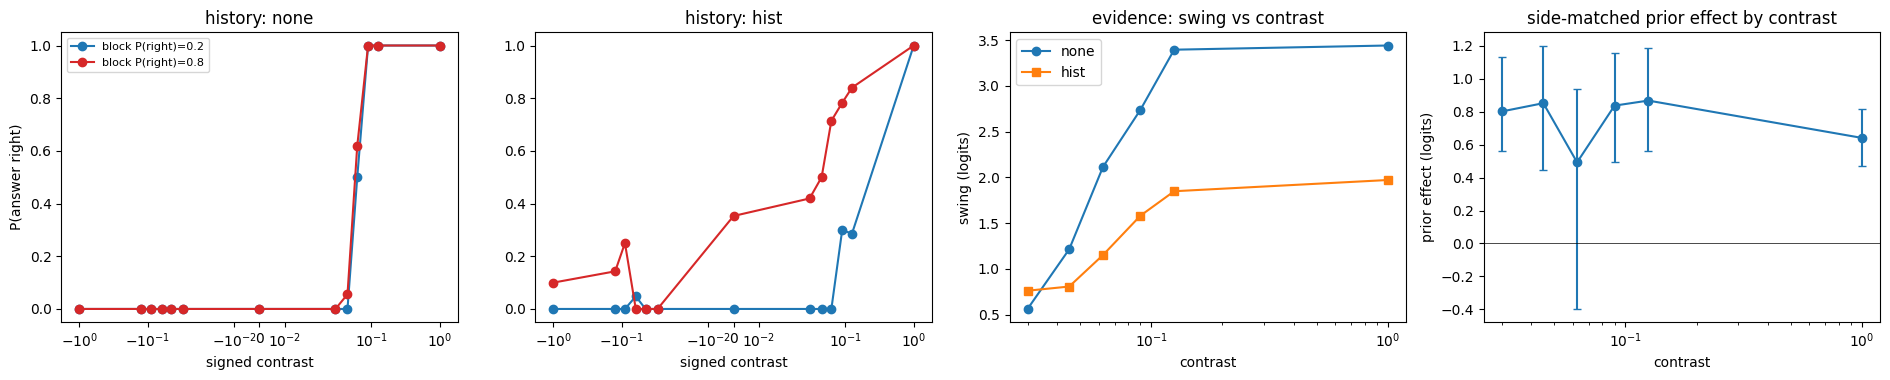

In [7]:
# ================= STAGE 3: ANALYSIS =================
SUMMARY = []                      # lines collected for the final share-back block
def say(s=""):
    print(s); SUMMARY.append(s)

def analyse():
    d = ROWS.copy()
    d["s"] = np.where(d.side == "right", 1, -1) * d.contrast
    d["prior"] = np.log(d.p_right / (1 - d.p_right))
    d["blk"] = np.round(d.p_right, 2)
    orders = ["none", "hist"]
    say(f"FORMAT: {CHOSEN} | rows {len(d)} | trials {d.t.nunique()} | median mass " +
        str(d.groupby("order").mass.median().round(3).to_dict()))

    # ---- [A] evidence ladder ----
    lad = {}
    for o in orders:
        g = d[(d.order == o) & (d.contrast > 0)]
        lad[o] = {c: h[h.side == "right"].delta.mean() - h[h.side == "left"].delta.mean() for c, h in g.groupby("contrast")}
    lad = pd.DataFrame(lad)
    lad["ratio"] = lad["hist"] / lad["none"]
    say("\n[A] swing (right - left mean delta, logits) by contrast; ratio = hist / none")
    say(lad.round(2).to_string())
    blank = d[d.contrast == 0].groupby("order").delta.mean().round(2).to_dict()
    say(f"blank-image mean delta (side bias b): {blank}")

    # ---- [B] fit on graded range, bootstrap over trials ----
    def fit(g):
        X = np.column_stack([np.ones(len(g)), g.s, g.prior]); return np.linalg.lstsq(X, g.delta.values, rcond=None)[0]
    rng = np.random.default_rng(0); fits = {}
    say(f"\n[B] fit delta = b + beta*s + gamma*prior (contrast <= {GRADED_MAX}); 95% bootstrap CI over trials")
    for o in orders:
        g = d[(d.order == o) & (d.contrast <= GRADED_MAX)]
        ts = g.t.unique(); byt = {t: g[g.t == t] for t in ts}
        est = fit(g); bs = np.array([fit(pd.concat([byt[t] for t in rng.choice(ts, len(ts))])) for _ in range(300)])
        lo, hi = np.percentile(bs, [2.5, 97.5], axis=0); fits[o] = (est, lo, hi)
        say(f"  {o:5s} b={est[0]:+.2f}  beta={est[1]:.1f} [{lo[1]:.1f},{hi[1]:.1f}]  "
            f"gamma={est[2]:+.3f} [{lo[2]:+.3f},{hi[2]:+.3f}]  (0.2-vs-0.8 gap -> {GAP * est[2]:+.2f} logits)")

    # ---- [C] side-matched paired prior effect ----
    w = d.pivot(index="t", columns="order", values="delta")
    meta = d[d.order == "none"].set_index("t").loc[w.index][["contrast", "side", "blk"]]
    keep = (meta.blk != 0.5).values
    cid = pd.factorize(np.where(meta.contrast.values == 0, "0.0|any", meta.contrast.astype(str) + "|" + meta.side))[0]
    cell_c = pd.Series(meta.contrast.values).groupby(cid).first().values
    is8 = (meta.blk == 0.8).values; ncell = cid.max() + 1
    diff = (w["hist"] - w["none"]).values
    def est_eff(idx, MIN_N=3):
        i = idx[keep[idx]]; c, m8, x = cid[i], is8[i], diff[i]
        n8 = np.bincount(c[m8], minlength=ncell); n2 = np.bincount(c[~m8], minlength=ncell)
        s8 = np.bincount(c[m8], x[m8], ncell); s2 = np.bincount(c[~m8], x[~m8], ncell)
        ok = (n8 >= MIN_N) & (n2 >= MIN_N)
        eff = np.where(ok, s8 / np.maximum(n8, 1) - s2 / np.maximum(n2, 1), 0.0)
        wt = np.where(ok, n8 * n2 / np.maximum(n8 + n2, 1), 0.0)
        per = {cc: ((wt[cell_c == cc] * eff[cell_c == cc]).sum() / wt[cell_c == cc].sum()
                    if wt[cell_c == cc].sum() > 0 else np.nan) for cc in np.unique(cell_c)}
        return ((wt * eff).sum() / wt.sum() if wt.sum() > 0 else np.nan), per
    N = len(w); overall, per = est_eff(np.arange(N))
    bs = [est_eff(rng.integers(0, N, N)) for _ in range(500)]
    lo, hi = np.nanpercentile([b[0] for b in bs], [2.5, 97.5])
    say(f"\n[C] side-matched prior effect (history minus none, block 0.8 minus 0.2): {overall:+.2f} logits "
        f"[{lo:+.2f},{hi:+.2f}]  -> gamma-equivalent {overall / GAP:+.3f}")
    tab = []
    for cc, v in per.items():
        arr = np.array([b[1][cc] for b in bs]); l, h = np.nanpercentile(arr, [2.5, 97.5])
        tab.append(dict(contrast=cc, effect=v, ci_lo=l, ci_hi=h))
    tabC = pd.DataFrame(tab); say(tabC.round(2).to_string(index=False))

    # ---- [D] prior in contrast units (for the mouse comparison) ----
    est_h = fits["hist"][0]; swn = lad["none"]
    half = 0.5 * swn.iloc[-1]; cs = np.array(swn.index, float); vs = swn.values
    c_half = np.nan
    for i in range(1, len(cs)):
        if vs[i - 1] < half <= vs[i]:
            c_half = cs[i - 1] + (half - vs[i - 1]) * (cs[i] - cs[i - 1]) / (vs[i] - vs[i - 1]); break
    shift = GAP * est_h[2] / est_h[1] if est_h[1] > 0 else np.nan
    say(f"\n[D] gamma/beta (hist) = {est_h[2] / est_h[1]:.4f}; prior boundary shift for the 0.2-vs-0.8 gap = {shift * 100:.1f}% contrast")
    say(f"    no-history half-swing contrast = {c_half * 100:.1f}%  -> shift / half-swing contrast = "
        f"{(shift / c_half if c_half == c_half else float('nan')):.2f}")
    say(f"    prior push / full evidence swing (none, 100%) = {GAP * est_h[2] / swn.iloc[-1]:.3f}")

    # ---- plots ----
    fig, axs = plt.subplots(1, 4, figsize=(19, 3.9))
    for ax, o in zip(axs[:2], orders):
        g = d[d.order == o].assign(says_right=lambda x: x.delta > 0)
        for pr, col in [(0.2, "tab:blue"), (0.8, "tab:red")]:
            h = g[np.isclose(g.blk, pr)].groupby("s").says_right.mean()
            ax.plot(h.index, h.values, "o-", color=col, label=f"block P(right)={pr}")
        ax.set_xscale("symlog", linthresh=0.03); ax.set_title(f"history: {o}"); ax.set_xlabel("signed contrast")
    axs[0].set_ylabel("P(answer right)"); axs[0].legend(fontsize=8)
    axs[2].plot(lad.index, lad["none"], "o-", label="none"); axs[2].plot(lad.index, lad["hist"], "s-", label="hist")
    axs[2].set_xscale("log"); axs[2].set_xlabel("contrast"); axs[2].set_ylabel("swing (logits)")
    axs[2].set_title("evidence: swing vs contrast"); axs[2].legend()
    t2 = tabC[tabC.contrast > 0]
    axs[3].errorbar(t2.contrast, t2.effect, yerr=[t2.effect - t2.ci_lo, t2.ci_hi - t2.effect], fmt="o-", capsize=3)
    axs[3].axhline(0, color="k", lw=0.5); axs[3].set_xscale("log"); axs[3].set_xlabel("contrast")
    axs[3].set_ylabel("prior effect (logits)"); axs[3].set_title("side-matched prior effect by contrast")
    plt.tight_layout(); plt.savefig(f"{OUTDIR}/analysis_plots.png", dpi=140); plt.show()
    return dict(fits=fits, lad=lad, overall=overall, tabC=tabC)

if STOP:
    print("STOP set: skipping analysis")
else:
    AN = analyse()

probes done for order = none
probes done for order = hist


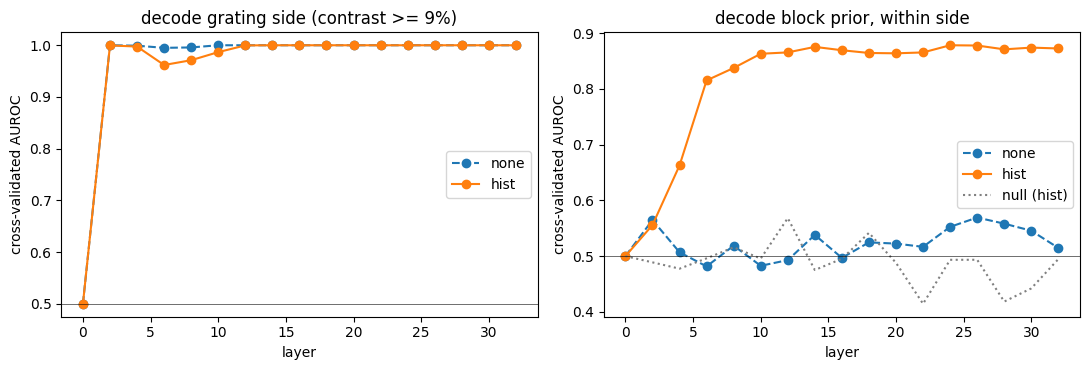


[E] probes at the answer position (AUROC, grouped CV by block; PCA-32 per layer)
      side_auc      block_auc       block_null
order     hist none      hist  none       hist
layer                                         
0         0.50  0.5      0.50  0.50       0.50
2         1.00  1.0      0.56  0.56       0.49
4         1.00  1.0      0.66  0.51       0.48
6         0.96  1.0      0.82  0.48       0.50
8         0.97  1.0      0.84  0.52       0.52
10        0.99  1.0      0.86  0.48       0.50
12        1.00  1.0      0.87  0.49       0.57
14        1.00  1.0      0.88  0.54       0.48
16        1.00  1.0      0.87  0.50       0.50
18        1.00  1.0      0.86  0.52       0.54
20        1.00  1.0      0.86  0.52       0.49
22        1.00  1.0      0.87  0.52       0.41
24        1.00  1.0      0.88  0.55       0.49
26        1.00  1.0      0.88  0.57       0.49
28        1.00  1.0      0.87  0.56       0.42
30        1.00  1.0      0.87  0.55       0.44
32        1.00  1.0      

In [8]:
# ================= STAGE 4: LAYER-WISE PROBES on the cached last-position residual stream =================
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def cv_auc(X, y, groups, stratify_groups=False):
    """Cross-validated AUROC with whole blocks held out, averaged over folds (per-fold AUROC avoids intercept artefacts).
    stratify_groups=True is for block-level labels (one label per block): blocks are spread over folds by label."""
    ug = np.unique(groups)
    if len(np.unique(y)) < 2:
        return np.nan
    if stratify_groups:
        lab_of = {g: int(y[groups == g][0]) for g in ug}
        n1 = sum(lab_of.values()); n0 = len(ug) - n1
        k = min(5, n0, n1)
        if k < 2:
            return np.nan
        fold_of = {}
        for lab in (0, 1):
            for i, g in enumerate([g for g in ug if lab_of[g] == lab]):
                fold_of[g] = i % k
        fold = np.array([fold_of[g] for g in groups])
    else:
        k = min(5, len(ug))
        if k < 2:
            return np.nan
        fold = np.zeros(len(y), int)
        for i, (_, te) in enumerate(GroupKFold(k).split(X, y, groups)):
            fold[te] = i
    aucs = []
    for i in range(k):
        te = fold == i; tr = ~te
        if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2:
            continue
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=500, class_weight="balanced"))
        clf.fit(X[tr], y[tr]); aucs.append(roc_auc_score(y[te], clf.decision_function(X[te])))
    return float(np.mean(aucs)) if aucs else np.nan

def run_probes():
    d = ROWS[ROWS.order == "none"].sort_values("t").reset_index(drop=True)      # trial-level metadata
    p = d.p_right.round(2).values
    blk_id = np.concatenate([[0], np.cumsum(p[1:] != p[:-1])])
    side_r = (d.side.values == "right").astype(int)
    rng = np.random.default_rng(0)
    layers = list(range(0, HS.shape[2], 2)); res = []
    for oi, o in enumerate(["none", "hist"]):
        for L in layers:
            X = HS[:, oi, L, :].astype(np.float32)
            Xp = PCA(n_components=min(32, X.shape[1], len(X) - 1), random_state=0).fit_transform(X)
            m = d.contrast.values >= 0.09
            a_side = cv_auc(Xp[m], side_r[m], blk_id[m])                       # grating side
            aucs, nulls = [], []
            for sd in ("left", "right"):                                      # block prior, WITHIN side (side and block are correlated)
                m2 = (d.side.values == sd) & (p != 0.5)
                y = (p[m2] == 0.8).astype(int); g = blk_id[m2]
                aucs.append(cv_auc(Xp[m2], y, g, stratify_groups=True))
                nn = []
                for _ in range(3):                                             # null: random labels per block
                    lab = {b: rng.integers(0, 2) for b in np.unique(g)}
                    nn.append(cv_auc(Xp[m2], np.array([lab[b] for b in g]), g, stratify_groups=True))
                nulls.append(np.nanmean(nn) if not np.all(np.isnan(nn)) else np.nan)
            res.append(dict(order=o, layer=L, side_auc=a_side,
                            block_auc=np.nanmean(aucs) if not np.all(np.isnan(aucs)) else np.nan,
                            block_null=np.nanmean(nulls) if not np.all(np.isnan(nulls)) else np.nan))
        print(f"probes done for order = {o}", flush=True)
    return pd.DataFrame(res)

if STOP:
    print("STOP set: skipping probes")
else:
    PROBE = run_probes(); PROBE.to_csv(f"{OUTDIR}/probe_results.csv", index=False)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    for o, st in (("none", "--"), ("hist", "-")):
        q = PROBE[PROBE.order == o]
        axs[0].plot(q.layer, q.side_auc, st, marker="o", label=o)
        axs[1].plot(q.layer, q.block_auc, st, marker="o", label=o)
    axs[1].plot(PROBE[PROBE.order == "hist"].layer, PROBE[PROBE.order == "hist"].block_null, ":", color="gray", label="null (hist)")
    axs[0].set_title("decode grating side (contrast >= 9%)"); axs[1].set_title("decode block prior, within side")
    for a in axs: a.set_xlabel("layer"); a.set_ylabel("cross-validated AUROC"); a.axhline(0.5, color="k", lw=0.4); a.legend()
    plt.tight_layout(); plt.savefig(f"{OUTDIR}/probe_plots.png", dpi=140); plt.show()
    say("\n[E] probes at the answer position (AUROC, grouped CV by block; PCA-32 per layer)")
    pv = PROBE.pivot(index="layer", columns="order", values=["side_auc", "block_auc"]).round(2)
    pv[("block_null", "hist")] = PROBE[PROBE.order == "hist"].set_index("layer").block_null.round(2)
    say(pv.to_string())

In [9]:
# ================= FINAL: SUMMARY BLOCK + ZIP =================
print("=" * 70); print("PASTE EVERYTHING BELOW BACK TO CLAUDE"); print("=" * 70)
print(f"MOCK={MOCK} | CONTRASTS={CONTRASTS} | N_SCREEN={N_SCREEN} | N_FULL={N_FULL}")
print("\nSCREEN (pass = swing_ratio >= %.2f and gamma >= %.2f and gamma_lo > 0):" % (MIN_SWING_RATIO, MIN_GAMMA))
print(SCREEN_TAB.round(3).to_string())
print(f"CHOSEN: {CHOSEN} ({WHY}) | STOP={STOP}\n")
for line in SUMMARY: print(line)
os.makedirs("/kaggle/working/share" if os.path.exists("/kaggle/working") else "./share", exist_ok=True)
SH = "/kaggle/working/share" if os.path.exists("/kaggle/working") else "./share"
for f in os.listdir(OUTDIR):
    if f.endswith((".csv", ".png")) and not f.startswith("full_rows_0"):
        shutil.copy(f"{OUTDIR}/{f}", f"{SH}/{f}")
open(f"{SH}/summary.txt", "w").write("\n".join(SUMMARY))
shutil.make_archive(SH, "zip", SH)
print(f"\nzip written: {SH}.zip  (small files only; the cached residual streams stay in {OUTDIR}/full_hs_*.npy)")

PASTE EVERYTHING BELOW BACK TO CLAUDE
MOCK=False | CONTRASTS=[0.0, 0.03, 0.045, 0.0625, 0.09, 0.125, 1.0] | N_SCREEN=300 | N_FULL=600

SCREEN (pass = swing_ratio >= 0.70 and gamma >= 0.25 and gamma_lo > 0):
                swing  swing_ratio      b   beta  gamma  gamma_lo  gamma_hi  median_mass  passes
format                                                                                          
counts30        1.653        0.492 -0.671  6.156  0.118     0.085     0.145        0.999   False
prob30          1.065        0.317  3.058  4.564 -0.010    -0.050     0.020        1.000   False
counts30+instr  1.065        0.317 -0.656  4.045  0.170     0.136     0.200        0.999   False
counts10        1.792        0.533 -0.482  6.346  0.227     0.180     0.273        0.999   False
prob30+instr    0.850        0.253  3.335  4.350 -0.018    -0.054     0.011        1.000   False
CHOSEN: counts10 (NO format passes; this is the closest one (min of the two criterion ratios)) | STOP=False

FORMA